# Задача 5. Более умный источник

**Что нужно**
1. Источник должен для заданной энергии испускать случайное число фотонов $n\sim\mathrm{Pois}(E\cdot Y)$.
2. Реализовать метод генерации фотонов из Задачи 2 как **генератор** Python (`yield`).
3. Модифицировать генератор так, чтобы он отдавал **по 100 фотонов** вместо одного.

Класс `Source` (модуль `source.py`) расширен двумя методами: `photons(E)` и `photon_batches(E, batch_size=100)`; в `Detector` добавлен `detect_stream` для потребления потока порций.

## Идея

Раньше `generate(E)` сразу создавал весь массив `(n, 3)`. Генератор делает это **лениво**: следующий фотон (порция) создаётся только когда его запрашивают через `next()` / `for`. Выгоды: память $O(1)$ вместо $O(n)$ (важно при больших энергиях), возможность обрабатывать фотоны «на лету» и прервать генерацию раньше.

Но генерация по одному фотону — это цикл Python с накладными расходами на каждый фотон (правило №1 лекции: циклы в Python медленные). Поэтому вторая версия отдаёт порции по 100 фотонов, а внутри порции работает векторизованный `numpy`.

In [1]:
import inspect
import time
import tracemalloc
import numpy as np
import matplotlib.pyplot as plt

from detector import Detector
from source import Source

plt.rcParams['figure.figsize'] = (6, 3)
plt.rcParams['figure.autolayout'] = True

print(inspect.getsource(Source.n_photons))
print(inspect.getsource(Source.photons))
print(inspect.getsource(Source.photon_batches))

    def n_photons(self, E: float, fluctuate: bool = True) -> int:
        if E < 0:
            raise ValueError("Энергия E не может быть отрицательной")
        mean = self.mean_photons(E)
        return int(self.rng.poisson(mean)) if fluctuate else int(round(mean))

    def photons(self, E: float):
        """Генератор: по одному фотону (единичный вектор формы (3,)) за обращение.

        Число фотонов n ~ Poisson(E*Y) разыгрывается при первом обращении к генератору;
        после n-го фотона генератор завершается (StopIteration).
        """
        n = self.n_photons(E, fluctuate=True)
        for _ in range(n):
            yield self.random_directions(1)[0]

    def photon_batches(self, E: float, batch_size: int = 100):
        """Генератор: по batch_size фотонов за обращение (массив (batch_size, 3)).

        Последняя порция может быть короче (остаток n % batch_size).
        Память O(batch_size) независимо от энергии события.
        """
        if batch_size < 1:
            r

## 1. Число фотонов — Пуассон со средним $E\cdot Y$

Реализовано в `Source.n_photons(E)`: `rng.poisson(Y*E)`. Число разыгрывается один раз при первом обращении к генератору и определяет, сколько фотонов он выдаст.

E = 0.1 МэВ: среднее      999.9 (ожидается     1000),  дисперсия/среднее = 0.986 (Пуассон: 1)
E = 1.0 МэВ: среднее    10000.0 (ожидается    10000),  дисперсия/среднее = 1.009 (Пуассон: 1)
E = 3.0 МэВ: среднее    29999.8 (ожидается    30000),  дисперсия/среднее = 0.981 (Пуассон: 1)


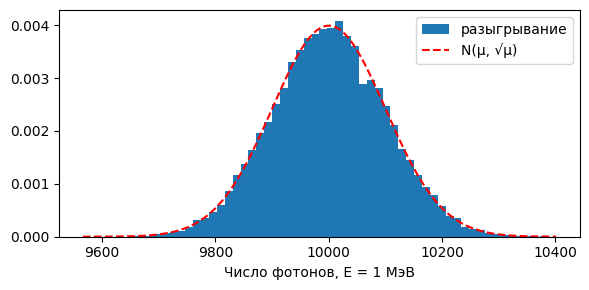

In [2]:
src = Source(Y=10_000, seed=1)

for E in (0.1, 1.0, 3.0):
    n = np.array([src.n_photons(E) for _ in range(20_000)])
    mu = src.Y * E
    print(f"E = {E} МэВ: среднее {n.mean():10.1f} (ожидается {mu:8.0f}),  "
          f"дисперсия/среднее = {n.var()/n.mean():.3f} (Пуассон: 1)")

n1 = np.array([src.n_photons(1.0) for _ in range(20_000)])
plt.hist(n1, bins=60, density=True, label='разыгрывание')
x = np.linspace(n1.min(), n1.max(), 300)
mu = src.Y
plt.plot(x, np.exp(-0.5*((x-mu)/np.sqrt(mu))**2)/np.sqrt(2*np.pi*mu), 'r--', label='N(μ, √μ)')
plt.xlabel('Число фотонов, E = 1 МэВ'); plt.legend(); plt.show()

## 2. Генератор `photons(E)`: по одному фотону

Функция с `yield` возвращает *объект-генератор*. Тело выполняется порциями до следующего `yield` при каждом `next()`.

In [3]:
gen = src.photons(0.0005)           # в среднем 5 фотонов
print("Тип:", type(gen).__name__, "| это генератор:", inspect.isgenerator(gen))

for k, p in enumerate(gen):
    print(f"фотон {k}: {p.round(3)}, |n| = {np.linalg.norm(p):.6f}")

Тип: generator | это генератор: True
фотон 0: [ 0.864 -0.502  0.037], |n| = 1.000000
фотон 1: [-0.846  0.386 -0.368], |n| = 1.000000
фотон 2: [-0.983 -0.18  -0.04 ], |n| = 1.000000
фотон 3: [ 0.165  0.343 -0.925], |n| = 1.000000
фотон 4: [-0.715 -0.312 -0.626], |n| = 1.000000


Генератор исчерпывается: после последнего фотона `next()` поднимает `StopIteration`, а повторный проход ничего не даст (нужен новый вызов `src.photons(E)`, с новым розыгрышем числа фотонов).

In [4]:
gen = src.photons(0.0003)
print(list(gen) != [], "|", list(gen), "<- второй проход по тому же генератору пуст")

gen = src.photons(0.0)              # E = 0 -> фотонов нет
print("E = 0:", list(gen))

True | [] <- второй проход по тому же генератору пуст
E = 0: []


## 3. Модифицированный генератор `photon_batches(E, batch_size=100)`: по 100 фотонов

In [5]:
b = src.photon_batches(0.0305)
batches = list(b)
print("Число порций:", len(batches))
print("Размеры порций:", [len(x) for x in batches][:8], "...", [len(x) for x in batches][-3:])
print("Форма порции:", batches[0].shape, "| последняя порция (остаток):", batches[-1].shape)
print("Всего фотонов:", sum(len(x) for x in batches))

Число порций: 4
Размеры порций: [100, 100, 100, 13] ... [100, 100, 13]
Форма порции: (100, 3) | последняя порция (остаток): (13, 3)
Всего фотонов: 313


Порция — это `numpy`-массив формы `(100, 3)` (последняя может быть короче: остаток $n \bmod 100$). Он совместим с `Detector.trace` и `Detector.detect`, так что порции можно сразу подавать в детектор.

## 4. Тесты

In [6]:
def test_generator_type_and_lazy():
    g = Source(seed=1).photons(1.0)
    assert inspect.isgenerator(g)
    gb = Source(seed=1).photon_batches(1.0)
    assert inspect.isgenerator(gb)

def test_photons_are_unit_vectors():
    for p in Source(seed=2).photons(0.5):
        assert p.shape == (3,)
        assert abs(np.linalg.norm(p) - 1) < 1e-12

def test_batch_sizes():
    s = Source(seed=3)
    for E in (0.0, 0.003, 0.01, 1.0, 2.3):
        b = list(s.photon_batches(E, 100))
        if not b:
            continue
        assert all(x.shape == (100, 3) for x in b[:-1])
        assert 1 <= len(b[-1]) <= 100
        assert all(abs(np.linalg.norm(x, axis=1) - 1).max() < 1e-12 for x in b)

def test_total_count_poisson():
    s = Source(Y=10_000, seed=4)
    E, K = 0.5, 5000
    n = np.array([sum(len(x) for x in s.photon_batches(E)) for _ in range(K)])
    mu = s.Y * E
    assert abs(n.mean() - mu) < 5 * np.sqrt(mu / K)
    assert abs(n.var() / mu - 1) < 5 * np.sqrt(2 / (K - 1))

def test_single_and_batch_same_count_distribution():
    E, K = 0.05, 4000
    a = Source(seed=5); b = Source(seed=6)
    na = np.array([sum(1 for _ in a.photons(E)) for _ in range(K)])
    nb = np.array([sum(len(x) for x in b.photon_batches(E)) for _ in range(K)])
    mu = 10_000 * E
    assert abs(na.mean() - nb.mean()) < 5 * np.sqrt(2 * mu / K)

def test_batches_are_isotropic():
    d = np.concatenate(list(Source(seed=7).photon_batches(100.0)))      # ~1e6 фотонов
    n = len(d)
    assert abs(n - 1e6) < 5 * 1e3
    assert np.all(np.abs(d.mean(axis=0)) < 5 / np.sqrt(3 * n))
    assert np.allclose(d.T @ d / n, np.eye(3) / 3, atol=5e-3)

def test_zero_energy_and_errors():
    assert list(Source(seed=8).photon_batches(0.0)) == []
    for bad in (lambda: list(Source().photon_batches(1.0, 0)),
                lambda: list(Source().photons(-1.0)),
                lambda: list(Source().photon_batches(-1.0))):
        try:
            bad()
        except ValueError:
            continue
        raise AssertionError("Ожидалось ValueError")

def test_reproducible():
    a = np.concatenate(list(Source(seed=9).photon_batches(0.3)))
    b = np.concatenate(list(Source(seed=9).photon_batches(0.3)))
    assert np.array_equal(a, b)

for name, f in list(globals().items()):
    if name.startswith("test_") and callable(f):
        f()
        print("OK ", name)

OK  test_generator_type_and_lazy
OK  test_photons_are_unit_vectors
OK  test_batch_sizes


OK  test_total_count_poisson


OK  test_single_and_batch_same_count_distribution


OK  test_batches_are_isotropic
OK  test_zero_energy_and_errors
OK  test_reproducible


## 5. Генератор в деле: событие целиком через поток порций

`Detector.detect_stream(origin, batches)` принимает любой итератор порций, накапливает попадания и в конце разыгрывает фотоэлектроны. Результат должен совпасть **статистически** с обычным `detect(origin, generate(E))` (точное совпадение невозможно — разные расходы случайных чисел).

Теория:          <Q> = 125.08, sigma = 13.70
photon_batches:  <Q> = 124.80 ± 0.42, sigma = 13.43
generate (всё сразу): <Q> = 126.20 ± 0.45, sigma = 14.36


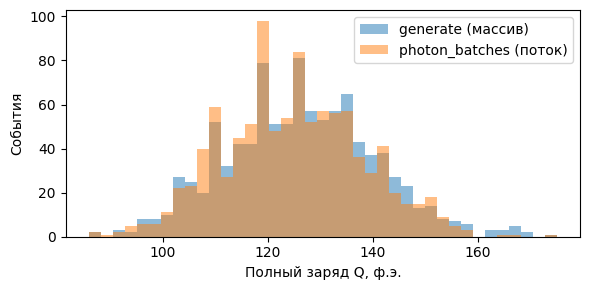

In [7]:
det = Detector(R=2.0, N=40, r=0.10, a=0.5, seed=10)
src = Source(Y=10_000, seed=11)
E, origin, K = 1.0, np.zeros(3), 1000

Q_stream = np.array([det.detect_stream(origin, src.photon_batches(E))[1].sum() for _ in range(K)])
Q_array  = np.array([det.detect(origin, src.generate(E))[1].sum() for _ in range(K)])

mu_H = src.Y * E * det.coverage
Q_th, s_th = det.a * mu_H, np.sqrt(det.a * (1 + det.a) * mu_H)
print(f"Теория:          <Q> = {Q_th:.2f}, sigma = {s_th:.2f}")
print(f"photon_batches:  <Q> = {Q_stream.mean():.2f} ± {Q_stream.std(ddof=1)/np.sqrt(K):.2f}, sigma = {Q_stream.std(ddof=1):.2f}")
print(f"generate (всё сразу): <Q> = {Q_array.mean():.2f} ± {Q_array.std(ddof=1)/np.sqrt(K):.2f}, sigma = {Q_array.std(ddof=1):.2f}")

assert abs(Q_stream.mean() - Q_th) < 5 * s_th / np.sqrt(K)
assert abs(Q_stream.mean() - Q_array.mean()) < 5 * np.hypot(Q_stream.std(), Q_array.std()) / np.sqrt(K)

b = np.linspace(Q_stream.min(), Q_stream.max(), 40)
plt.hist(Q_array, bins=b, alpha=0.5, label='generate (массив)')
plt.hist(Q_stream, bins=b, alpha=0.5, label='photon_batches (поток)')
plt.xlabel('Полный заряд Q, ф.э.'); plt.ylabel('События'); plt.legend(); plt.show()

## 6. Зачем порции: скорость и память

Сравним три способа получить направления фотонов события: всё сразу (`generate`), по одному фотону через генератор (`photons`) и порциями по 100 (`photon_batches`).

In [8]:
def drain_single(s, E):
    return sum(1 for _ in s.photons(E))

def drain_batches(s, E, bs=100):
    return sum(len(x) for x in s.photon_batches(E, bs))

def drain_all(s, E):
    return len(s.generate(E))

E = 1.0
rows = []
for name, f in [("generate (всё сразу)", drain_all),
                ("photons (по 1)", drain_single),
                ("photon_batches (по 100)", drain_batches)]:
    s = Source(seed=1)
    t0 = time.perf_counter()
    for _ in range(20):
        f(s, E)
    dt = (time.perf_counter() - t0) / 20
    rows.append((name, dt))
    print(f"{name:26s} {dt*1e3:9.2f} мс на событие E = 1 МэВ (~1e4 фотонов)")

print(f"\nГенерация по одному медленнее порций по 100 в ~{rows[1][1]/rows[2][1]:.0f} раз")

generate (всё сразу)            0.50 мс на событие E = 1 МэВ (~1e4 фотонов)


photons (по 1)                106.02 мс на событие E = 1 МэВ (~1e4 фотонов)
photon_batches (по 100)         1.68 мс на событие E = 1 МэВ (~1e4 фотонов)

Генерация по одному медленнее порций по 100 в ~63 раз


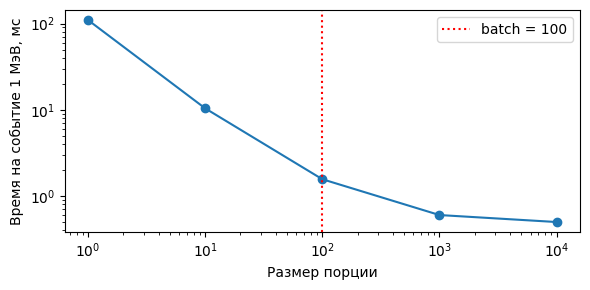

In [9]:
sizes = [1, 10, 100, 1000, 10_000]
times = []
for bs in sizes:
    s = Source(seed=1)
    t0 = time.perf_counter()
    for _ in range(5):
        drain_batches(s, 1.0, bs)
    times.append((time.perf_counter() - t0) / 5)

plt.loglog(sizes, np.array(times) * 1e3, 'o-')
plt.axvline(100, color='r', ls=':', label='batch = 100')
plt.xlabel('Размер порции'); plt.ylabel('Время на событие 1 МэВ, мс'); plt.legend(); plt.show()

Память: для события с большой энергией (100 МэВ $\approx 10^6$ фотонов) массив `(n, 3)` занимает десятки мегабайт, а поток порций — константу.

In [10]:
E_big = 100.0                      # ~1e6 фотонов

def peak_memory(func):
    tracemalloc.start()
    func()
    _, peak = tracemalloc.get_traced_memory()
    tracemalloc.stop()
    return peak / 1e6

m_all = peak_memory(lambda: drain_all(Source(seed=2), E_big))
m_bat = peak_memory(lambda: drain_batches(Source(seed=2), E_big, 100))
print(f"E = 100 МэВ: пик памяти generate = {m_all:.1f} МБ, photon_batches(100) = {m_bat:.3f} МБ")

E = 100 МэВ: пик памяти generate = 64.0 МБ, photon_batches(100) = 0.012 МБ


## Выводы

* **Пуассоновское число фотонов.** `Source.n_photons(E)` возвращает $n\sim\mathrm{Pois}(E\,Y)$; проверено: среднее $E\,Y$, дисперсия $=$ среднему.
* **Генератор.** `Source.photons(E)` — функция с `yield`, лениво выдаёт по одному изотропному единичному вектору и завершается после $n$ фотонов; число фотонов разыгрывается при первом обращении.
* **Порции по 100.** `Source.photon_batches(E, batch_size=100)` отдаёт массивы `(100, 3)` (последний — остаток). Это ускоряет генерацию в десятки раз по сравнению с «по одному фотону» (внутри порции работает векторизованный `numpy`; цикл Python делается раз на 100 фотонов), а память остаётся $O(\text{batch})$ в отличие от массива на всё событие.
* **Совместимость с детектором.** `Detector.detect_stream` потребляет поток порций; распределение собранного заряда совпадает с получаемым из `generate` и с теорией ($\langle Q\rangle=aYEf$, $\sigma^2=a(1+a)YEf$).